# 09 · Work System, mô hình chuẩn, khai phá và kiểm định tuân thủ (Chương 1 và Chương 5)

## 1. Mục tiêu và buổi học áp dụng

Trả lời **câu hỏi quản trị 1** (*quy trình thực tế chạy thế nào?*) và **câu hỏi 3** (*bao nhiêu ca lệch khỏi quy trình chuẩn, lệch ở đâu?*). Áp dụng **Buổi 1 — Work System, BPMN 2.0** (pool, lane, gateway) và **Buổi 5 — khai phá quy trình** (Alpha, Heuristics, Inductive Miner), **Petri net** và **kiểm định tuân thủ bằng token replay** (fitness, precision, generalization, simplicity).

## 2. Đầu vào

Run `outputs/process/<run>` (bước C: `c_conformance/`), loader kiểm fingerprint.

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
rm = run.manifest["config"]["reference_model"]
display(Markdown(f"**Mô hình chuẩn đã duyệt:** `{rm['approved']}` — điểm đầu `{rm['start']}`, "
                 f"kết thúc {rm['ends']}"))
display(pd.DataFrame({"cung được phép": rm["arcs"]}))
display(pd.DataFrame(run.manifest["config"]["alternative_models"]))

**Mô hình chuẩn đã duyệt:** `True` — điểm đầu `CREATE`, kết thúc ['DONE', 'Rejected']

,cung được phép
0,CREATE -> Inbox
1,CREATE -> To Investigate
2,CREATE -> Rejected
3,Inbox -> To Investigate
4,Inbox -> Rejected
5,To Investigate -> INVESTIGATED
6,To Investigate -> Rejected
7,INVESTIGATED -> To Do
8,INVESTIGATED -> Rejected
9,To Do -> In Progress


,id,label,extra_arcs
0,fast_track,Luồng nhanh (ứng viên TO-BE): cho phép bỏ pha điều tra,[CREATE -> To Do]


## 3. Dữ liệu và giả định

- Log mức **trạng thái**: activity = `CREATE` + tên trạng thái Jira, cả 161 ca (mô tả, không có bước học).
- **Mô hình chuẩn là giả định của tác giả** (Quyết định 4), đã được duyệt ngày 26/10 (Quyết định 8), gồm **giả định A1**: `CREATE` là vào `Inbox` ngầm định, nên các cung ra của `Inbox` cũng là cung ra của `CREATE` (Ruling 83).
- **Mô hình "luồng nhanh"** = mô hình chuẩn + `CREATE → To Do`. Đây **KHÔNG phải mô hình chuẩn** mà là ứng viên TO-BE cho Chương 4; chỉ đặt cạnh để đo số ca được giải thích thêm.
- **Cờ quy tắc chỉ đếm**, không kết luận lỗi; cờ 0 ca vẫn được báo (quy trình được tuân thủ ở điểm đó).
- Lane BPMN = vai trò người chuyển ca **ra** khỏi trạng thái nhiều nhất (Ruling 84); mức vai trò, không cá nhân.
- Work System: ô không suy ra được từ log ghi rõ là **giả định đề bài**; `bot`/`unknown` không là người tham gia.

## 4. Kết quả

### 4.1 Work System của quy trình xử lý bug (Buổi 1)

In [3]:
display(run.csv("c_conformance/work_system.csv"))

,component,content,evidence
0,Khách hàng,Người dùng/khách hàng gặp lỗi (giả định đề bài) và các vai trò nội bộ báo lỗi.,Vai trò tạo issue: Eng 54; SQA 44; unknown 26; PO 16; __MISSING_ROLE__ 11
1,Sản phẩm/dịch vụ,Lỗi được sửa và đóng (DONE) hoặc quyết định không sửa (Rejected); thay đổi mã liên kết commit/MR.,DONE 83; Rejected 78; LINK_COMMIT 342; LINK_MERGE_REQUEST 95 event
2,Quy trình và hoạt động,"Chuỗi trạng thái Jira từ tạo đến đóng, xen các hoạt động sửa trường, gán người, liên kết.","10 trạng thái (DONE, INVESTIGATED, In Progress, In Test, Inbox, OPEN, Rejected, To Do, To Invest..."
3,Người tham gia,Các vai trò con người trong log (không phân tích cá nhân).,PO 1296; Eng 489; SQA 168; RTE 43; Integrator 21; Support/Mgr 11; PM 7; Software Architect 5; kh...
4,Thông tin,"Mô tả lỗi, phân loại backlog, phiên bản sửa, epic, story point, file đính kèm, liên kết issue.",Hoạt động trên trường thông tin: ADD_ISSUE_LINK 384; EDIT_DESCRIPTION 357; UPDATE_BACKLOG_CLASSI...
5,Công nghệ,"Jira (theo dõi issue, workflow) tích hợp hệ thống quản lý mã nguồn qua bot.",bot 2230/5126 event (43.5%) trong full view
6,Môi trường,"Một team trong công ty phần mềm lớn, có áp lực phát hành (giả định đề bài + trường dữ liệu).",Giai đoạn 2021-06 → 2022-08; UPDATE_BLOCKING_FOR_RELEASE 47 event
7,Hạ tầng,"Máy chủ Jira, Git/merge request và tích hợp tự động dùng chung (giả định đề bài; log không mô tả).","Dấu vết tích hợp: LINK_COMMIT 342, LINK_MERGE_REQUEST 95 event trong core view"


### 4.2 Mô hình chuẩn: BPMN (pool + lane + XOR) và Petri net

File BPMN 2.0 (`reference_model.bpmn`) mở được bằng bpmn.io/Camunda Modeler; hình dưới là bản Graphviz.

,lane (vai trò)
INVESTIGATED,PO
In Progress,Eng
In Test,SQA
Inbox,PO
To Do,PO
To Investigate,PO


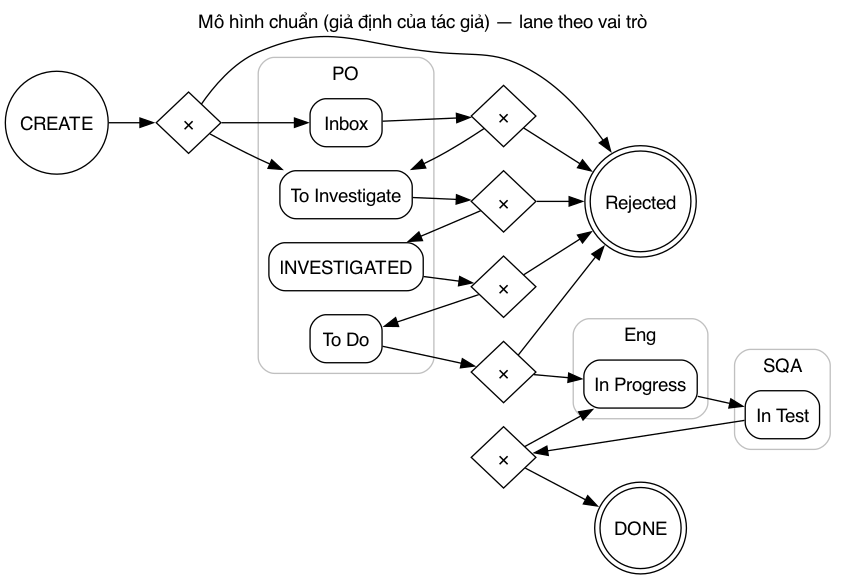

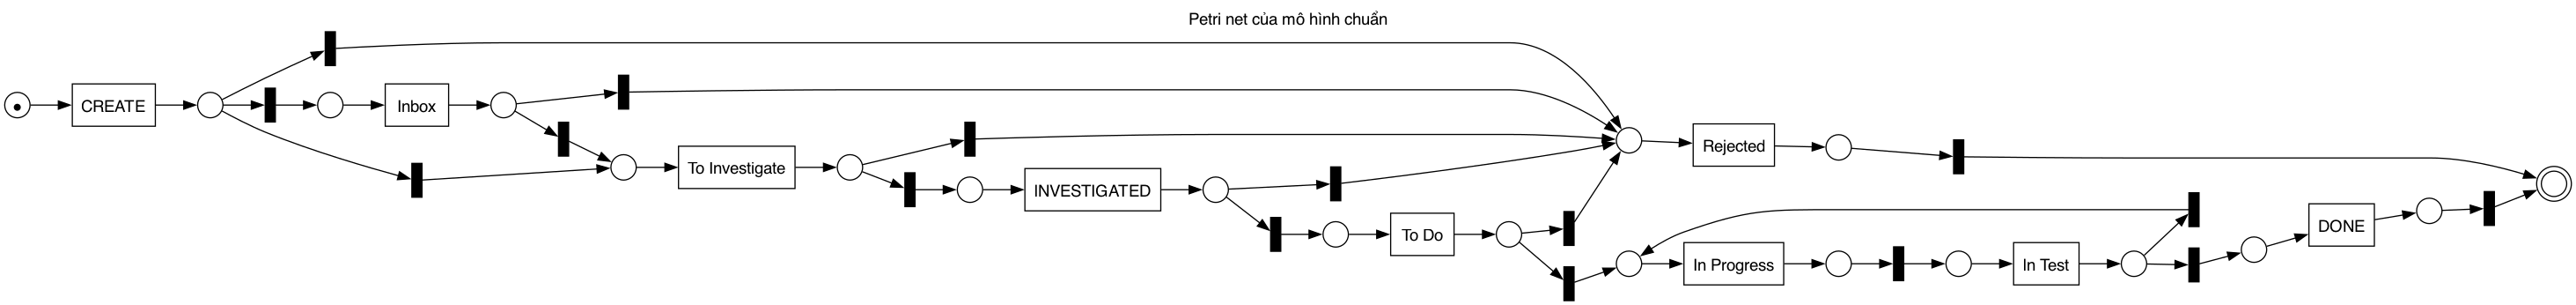

In [4]:
from IPython.display import Image
display(pd.Series(run.json("c_conformance/lanes.json"), name="lane (vai trò)").to_frame())
display(Image(filename=str(run.path("c_conformance/reference_model.png"))))
display(Image(filename=str(run.path("c_conformance/reference_net.png"))))

### 4.3 Khai phá AS-IS: Alpha, Heuristics, Inductive (Buổi 5)

,id,miner,params,fitness,perc_fit_traces,precision,generalization,simplicity,n_places,n_transitions,n_invisible
0,alpha,alpha,{},0.616,0.000,0.453,0.725,0.433,15,11,0
1,heuristics,heuristics,"{""dependency_threshold"": 0.5}",0.921,37.888,1.000,0.567,0.639,19,27,16
2,inductive,inductive,"{""noise_threshold"": 0.0}",1.000,100.000,0.548,0.781,0.667,12,20,9
3,inductive_infrequent,inductive,"{""noise_threshold"": 0.2}",0.979,78.261,0.855,0.669,0.733,18,26,15


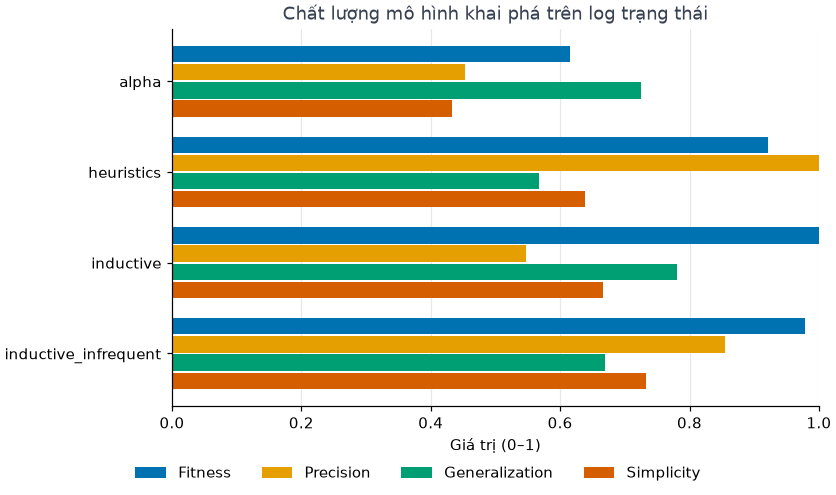

**alpha**

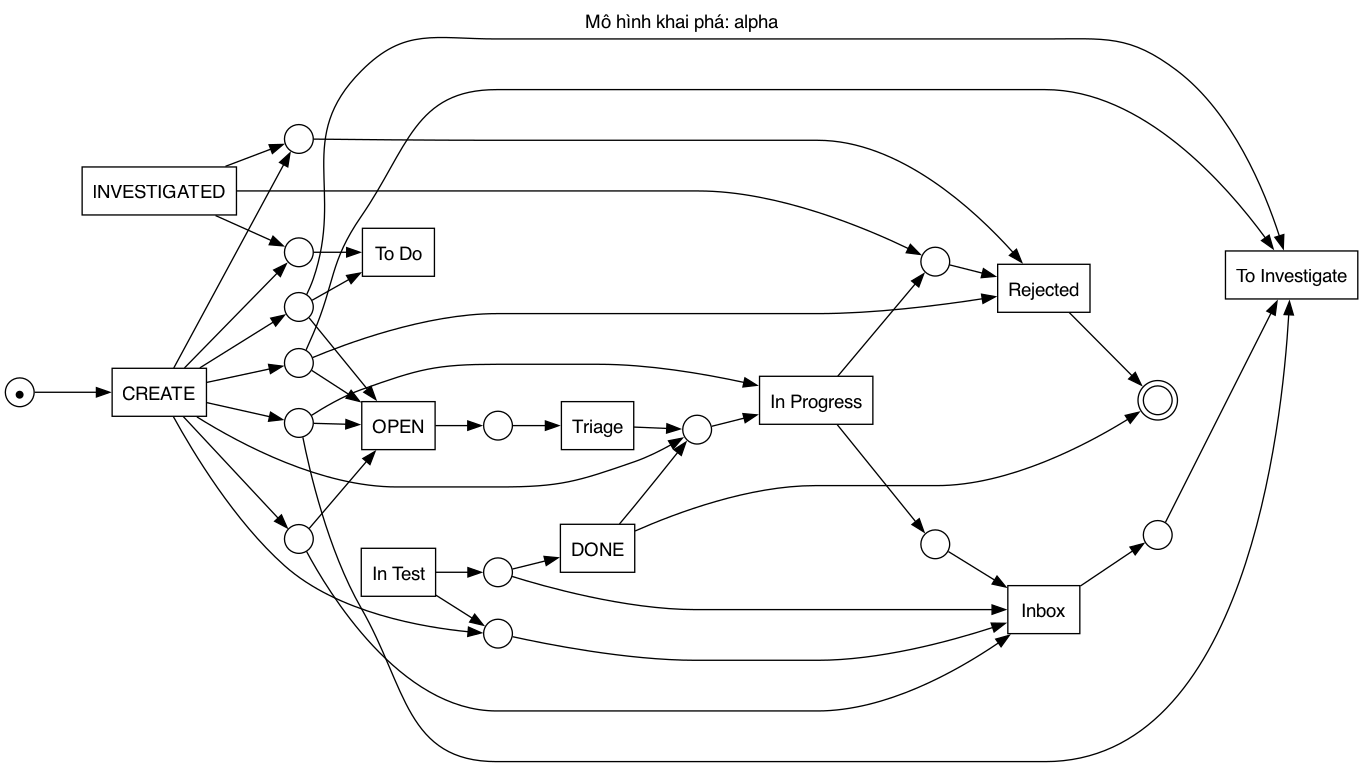

**heuristics**

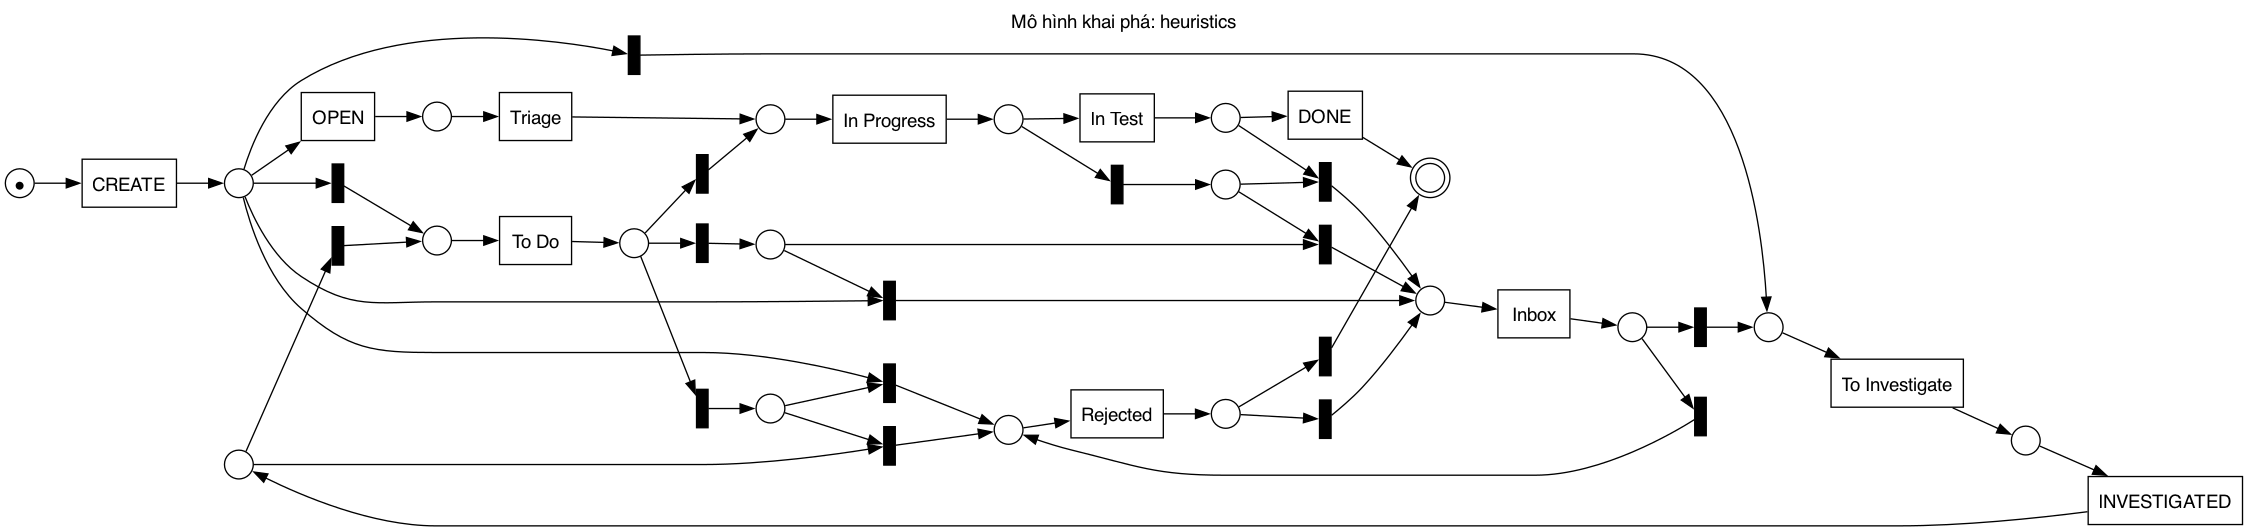

**inductive**

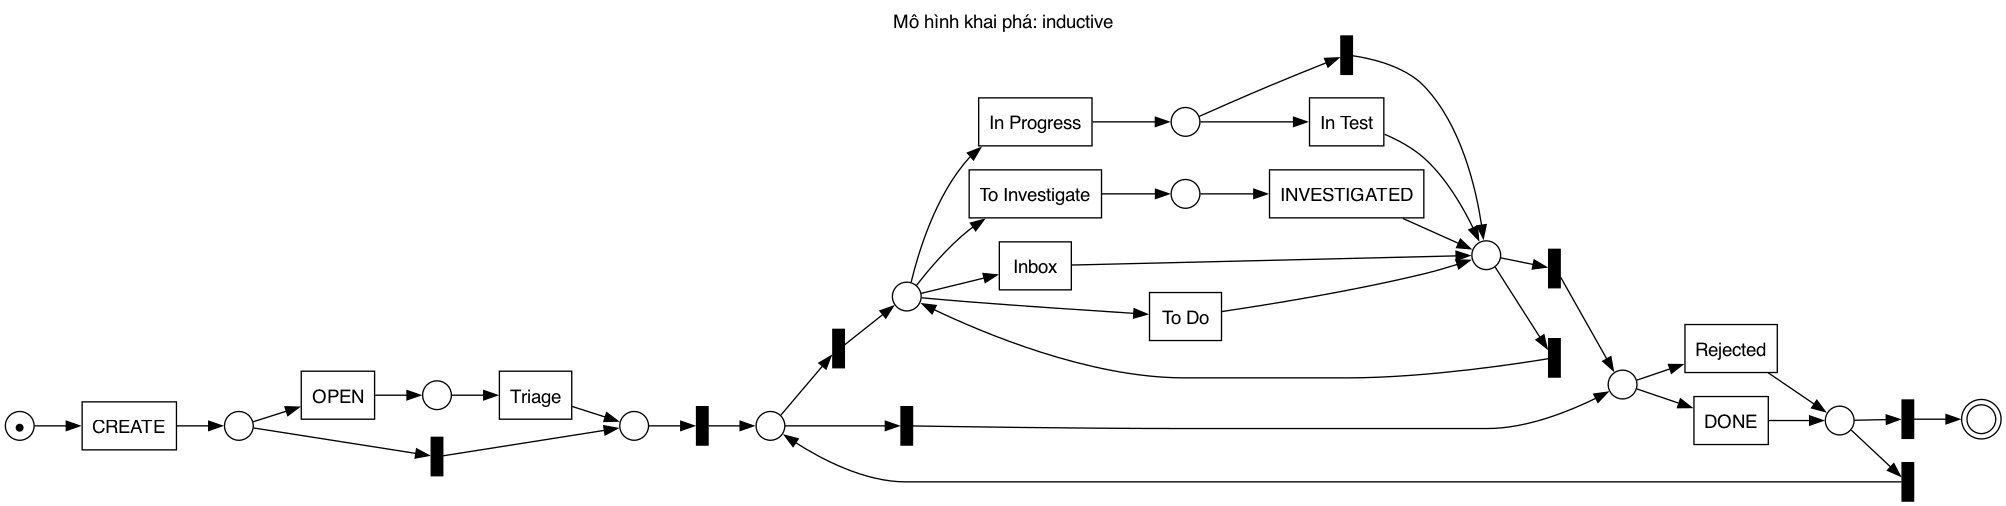

**inductive_infrequent**

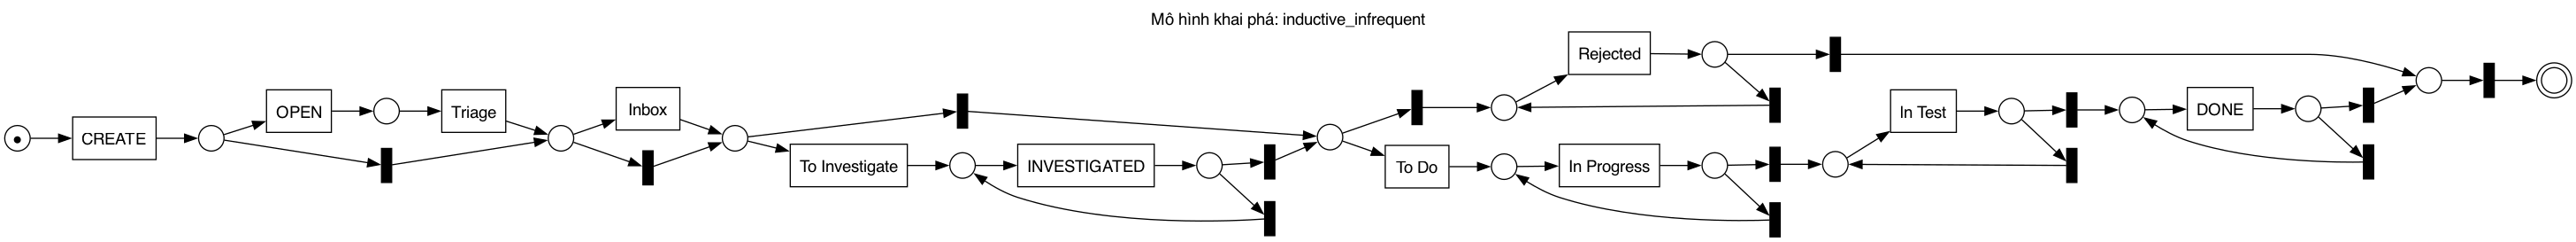

In [5]:
quality = run.csv("c_conformance/discovery_quality.csv")
display(quality)
_ = run.show(pp.plot_discovery_quality(quality))
for model_id in quality["id"]:
    display(Markdown(f"**{model_id}**"))
    display(Image(filename=str(run.path(f"c_conformance/models/{model_id}.png"))))

### 4.4 Token replay trên mô hình chuẩn, đặt cạnh mô hình "luồng nhanh"

In [6]:
if run.path("c_conformance/replay_summary.json").is_file():
    summary = run.json("c_conformance/replay_summary.json")
    display(pd.DataFrame(summary["by_branch"]).T)
    display(pd.Series(summary["model_quality"], name="mô hình chuẩn").to_frame())
    display(run.csv("c_conformance/replay_comparison.csv"))
    display(Markdown("**Ca được giải thích thêm khi thêm `CREATE → To Do` (mô hình phụ, KHÔNG phải chuẩn)**"))
    display(run.csv("c_conformance/replay_gained_cases.csv"))
else:
    display(Markdown(f"Replay chưa chạy: {run.json('c_conformance/status.json')['reference_replay']}"))

,n_cases,mean_trace_fitness,n_fit,share_fit
all,161.000,0.967,105.000,0.652
DONE,83.000,0.952,39.000,0.470
Rejected,78.000,0.984,66.000,0.846


,mô hình chuẩn
fitness,0.965
perc_fit_traces,65.217
precision,0.915
generalization,0.782
simplicity,0.786
n_places,19.000
n_transitions,25.000
n_invisible,16.000


,model,n_cases,mean_fitness,n_fit,share_fit,n_newly_fit_vs_reference
0,reference,161,0.967,105,0.652,0
1,fast_track,161,0.985,130,0.807,25


**Ca được giải thích thêm khi thêm `CREATE → To Do` (mô hình phụ, KHÔNG phải chuẩn)**

,model,case_id,terminal_status
0,fast_track,bug:TI-4759,DONE
1,fast_track,bug:TI-4820,DONE
2,fast_track,bug:TI-4876,DONE
3,fast_track,bug:TI-4890,DONE
4,fast_track,bug:TI-4902,DONE
5,fast_track,bug:TI-4935,DONE
6,fast_track,bug:TI-4966,Rejected
7,fast_track,bug:TI-5016,DONE
8,fast_track,bug:TI-5091,DONE
9,fast_track,bug:TI-5176,DONE


### 4.5 Lệch ở đâu: cung ngoài mô hình, theo nhánh và cập nhật bù

In [7]:
arcs = run.csv("c_conformance/arc_table.csv")
display(arcs[~arcs.in_model])
if run.path("c_conformance/deviation_breakdown.csv").is_file():
    display(run.csv("c_conformance/deviation_breakdown.csv"))
    replay = run.csv("c_conformance/replay_cases.csv")
    display(Markdown("**Các ca có fitness thấp nhất (mô hình chuẩn)**"))
    display(replay.sort_values(["trace_fitness", "case_id"]).head(10))

,source,target,in_model,count,n_cases,median_wait_days,example_cases
0,CREATE,To Do,False,37,37,1.102,"bug:TI-4751, bug:TI-4759, bug:TI-4811"
1,To Do,Inbox,False,11,11,6.842,"bug:TI-4748, bug:TI-4751, bug:TI-5118"
2,INVESTIGATED,To Investigate,False,5,5,2.116,"bug:TI-4748, bug:TI-5153, bug:TI-5480"
3,In Progress,To Do,False,5,5,0.015,"bug:TI-4617, bug:TI-4811, bug:TI-5118"
4,DONE,In Progress,False,4,4,0.003,"bug:TI-4584, bug:TI-5362, bug:TI-5564"
5,Rejected,Inbox,False,4,4,0.001,"bug:TI-4671, bug:TI-4723, bug:TI-4871"
6,In Progress,Rejected,False,2,2,0.000,"bug:TI-4584, bug:TI-5674"
7,CREATE,In Progress,False,1,1,0.073,bug:TI-6203
8,CREATE,OPEN,False,1,1,0.035,bug:TI-5770
9,In Progress,Inbox,False,1,1,0.000,bug:TI-5564


,category,branch,n_cases,n_occurrences,n_occ_in_burst,n_cases_only_in_burst,n_cases_outside_burst,examples_only_in_burst,examples_outside_burst
0,CREATE → To Do,all,37,37,9,9,28,"bug:TI-4811, bug:TI-4820, bug:TI-4935, bug:TI-5200, bug:TI-5564","bug:TI-4751, bug:TI-4759, bug:TI-4876, bug:TI-4890, bug:TI-4902"
1,CREATE → To Do,DONE,30,30,7,7,23,"bug:TI-4811, bug:TI-4820, bug:TI-4935, bug:TI-5564, bug:TI-5608","bug:TI-4751, bug:TI-4759, bug:TI-4876, bug:TI-4890, bug:TI-4902"
2,CREATE → To Do,Rejected,7,7,2,2,5,"bug:TI-5200, bug:TI-5598","bug:TI-4966, bug:TI-5260, bug:TI-5261, bug:TI-5378, bug:TI-6150"
3,To Do → Inbox,all,11,11,10,10,1,"bug:TI-4748, bug:TI-4751, bug:TI-5118, bug:TI-5139, bug:TI-5200",bug:TI-5260
4,To Do → Inbox,DONE,6,6,6,6,0,"bug:TI-4748, bug:TI-4751, bug:TI-5118, bug:TI-5139, bug:TI-5347",NaN
5,To Do → Inbox,Rejected,5,5,4,4,1,"bug:TI-5200, bug:TI-5378, bug:TI-5598, bug:TI-6150",bug:TI-5260
6,Lùi trạng thái,all,23,26,20,17,6,"bug:TI-4617, bug:TI-4748, bug:TI-4751, bug:TI-4811, bug:TI-5118","bug:TI-4686, bug:TI-5153, bug:TI-5260, bug:TI-5269, bug:TI-5480"
7,Lùi trạng thái,DONE,16,19,15,12,4,"bug:TI-4617, bug:TI-4748, bug:TI-4751, bug:TI-4811, bug:TI-5118","bug:TI-4686, bug:TI-5153, bug:TI-5269, bug:TI-5480"
8,Lùi trạng thái,Rejected,7,7,5,5,2,"bug:TI-5200, bug:TI-5378, bug:TI-5598, bug:TI-5674, bug:TI-6150","bug:TI-5260, bug:TI-6105"
9,Mở lại,all,8,9,8,7,1,"bug:TI-4584, bug:TI-4671, bug:TI-4723, bug:TI-4871, bug:TI-5362",bug:TI-4872


**Các ca có fitness thấp nhất (mô hình chuẩn)**

,case_id,trace_fitness,is_fit,missing,remaining,consumed,produced,unknown_activities,variant,terminal_status
42,bug:TI-4966,0.833,False,1,1,6,6,NaN,CREATE > To Do > Rejected,Rejected
69,bug:TI-5261,0.833,False,1,1,6,6,NaN,CREATE > To Do > Rejected,Rejected
23,bug:TI-4811,0.846,False,2,2,13,13,NaN,CREATE > To Do > In Progress > To Do > In Progress > In Test > DONE,DONE
157,bug:TI-6208,0.846,False,2,2,13,13,NaN,CREATE > To Do > In Progress > To Do > In Progress > In Test > DONE,DONE
0,bug:TI-4584,0.875,False,3,3,24,24,NaN,CREATE > To Investigate > INVESTIGATED > To Do > In Progress > In Test > DONE > In Progress > Re...,DONE
7,bug:TI-4671,0.875,False,1,1,8,8,NaN,CREATE > Rejected > Inbox > Rejected,Rejected
30,bug:TI-4872,0.875,False,1,1,8,8,NaN,CREATE > Rejected > Inbox > Rejected,Rejected
68,bug:TI-5260,0.875,False,1,1,8,8,NaN,CREATE > To Do > Inbox > Rejected,Rejected
132,bug:TI-5770,0.875,False,1,1,8,8,"OPEN, Triage",CREATE > OPEN > Triage > In Progress > In Test > DONE,DONE
156,bug:TI-6203,0.875,False,1,1,8,8,NaN,CREATE > In Progress > In Test > DONE,DONE


### 4.6 Cờ quy tắc (đếm, không kết luận lỗi)

,flag,label,n_cases,share_cases,n_occurrences,n_done,n_rejected,example_cases
0,skip_investigation,Bỏ pha điều tra,39,0.242,39,32,7,"bug:TI-4751, bug:TI-4759, bug:TI-4811, bug:TI-4820, bug:TI-4876"
1,direct_reject,CREATE → Rejected trực tiếp,26,0.161,26,1,25,"bug:TI-4616, bug:TI-4649, bug:TI-4671, bug:TI-4723, bug:TI-4726"
2,reject_after_work,Rejected sau khi đã In Progress (công sức bị bỏ),2,0.012,2,1,1,"bug:TI-4584, bug:TI-5674"
3,reopen_done,Mở lại sau DONE,4,0.025,4,4,0,"bug:TI-4584, bug:TI-5362, bug:TI-5564, bug:TI-5591"
4,back_to_inbox,Lùi về Inbox từ trạng thái sau,17,0.106,17,9,8,"bug:TI-4671, bug:TI-4686, bug:TI-4723, bug:TI-4748, bug:TI-4751"
5,progress_not_from_todo,Vào In Progress không qua To Do,6,0.037,6,6,0,"bug:TI-4584, bug:TI-5362, bug:TI-5564, bug:TI-5591, bug:TI-5770"
6,backfill,Đổi trạng thái trong đợt cập nhật bù,69,0.429,165,55,14,"bug:TI-4584, bug:TI-4596, bug:TI-4599, bug:TI-4617, bug:TI-4671"


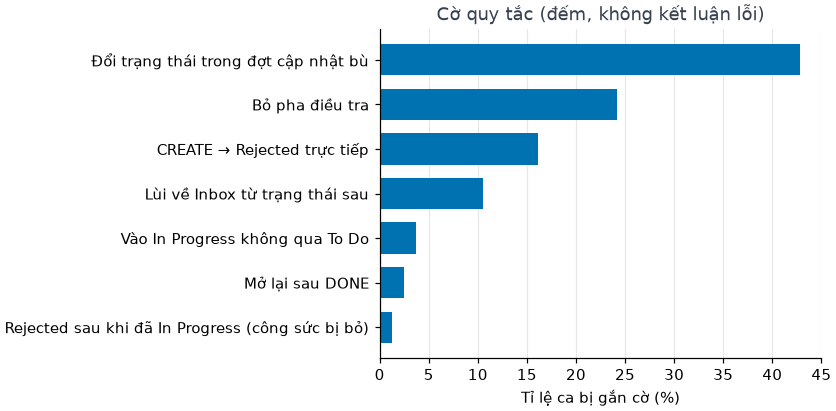

In [8]:
flags = run.csv("c_conformance/flag_summary.csv")
display(flags)
_ = run.show(pp.plot_flag_summary(flags))

### 4.7 Enhancement: thời gian chờ trên từng cung của mô hình chuẩn

Trung vị thời gian nằm ở trạng thái nguồn (ngày làm việc) trước khi đi theo cung; cung chưa từng xảy ra có số lần 0.

In [9]:
display(arcs[arcs.in_model].sort_values("count", ascending=False)[
    ["source", "target", "count", "n_cases", "median_wait_days", "example_cases"]])
if run.path("c_conformance/unobserved_arc_precision.csv").is_file():
    display(Markdown("**Cung có trong mô hình nhưng chưa từng xảy ra: ảnh hưởng tới precision**"))
    display(run.csv("c_conformance/unobserved_arc_precision.csv"))

,source,target,count,n_cases,median_wait_days,example_cases
15,To Investigate,INVESTIGATED,114,106,10.876,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
16,CREATE,To Investigate,95,95,2.084,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
17,In Progress,In Test,91,84,1.011,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
18,To Do,In Progress,90,82,0.001,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
19,In Test,DONE,87,83,2.994,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
20,INVESTIGATED,To Do,62,59,0.000,"bug:TI-4584, bug:TI-4596, bug:TI-4599"
21,INVESTIGATED,Rejected,47,47,1.104,"bug:TI-4724, bug:TI-4725, bug:TI-4745"
22,CREATE,Rejected,26,26,2.971,"bug:TI-4616, bug:TI-4649, bug:TI-4671"
23,Inbox,To Investigate,14,14,0.000,"bug:TI-4723, bug:TI-4748, bug:TI-4751"
24,To Do,Rejected,5,5,144.032,"bug:TI-4683, bug:TI-4966, bug:TI-5200"


**Cung có trong mô hình nhưng chưa từng xảy ra: ảnh hưởng tới precision**

,source,target,count,precision_with,precision_without,fitness_with,fitness_without,note
0,To Investigate,Rejected,0,0.915,0.991,0.965,0.965,NaN


## 5. Quá trình nghiên cứu

- **Quy tắc kiểm định đổi theo người dùng** (Quyết định 4): ba quy tắc agent đề xuất ban đầu bị đánh giá là chưa đủ (hai quy tắc luôn đúng theo cách dựng dữ liệu). Thay bằng mô hình chuẩn dạng danh sách cung + 7 cờ đếm.
- **Điểm dừng trước replay**: mô hình chuẩn được trình bày một lần; người dùng duyệt phương án (a), giữ giả định A1, yêu cầu thêm replay phụ "luồng nhanh", giữ cung `To Investigate → Rejected` dù 0 lần xảy ra, và báo sai lệch theo nhánh/cập nhật bù (Quyết định 8).
- **Petri net** dựng theo cách "mỗi activity một transition, mỗi cung một transition ẩn" để nhãn không trùng và token replay chạy đúng (Ruling 71).
- **Hình không tái lập được** ở lần đầu: pm4py đặt tên place của Alpha và transition ẩn của Heuristics theo thứ tự duyệt set (đổi theo `PYTHONHASHSEED`). Sửa bằng sắp nút theo cấu trúc (Ruling 85); hai run với seed băm khác nhau cho file giống hệt.
- **Số cờ khác "sự thật đã đo"** (26 so với 22; 39 so với 22) do định nghĩa: "sự thật" đếm đúng nguyên biến thể, cờ đếm rộng hơn; cả hai được tính lại bằng pandas thô và khớp (Ruling 86).
- **Fitness token so với tỉ lệ ca khớp**: fitness token của mô hình chuẩn rất cao vì một token thiếu chỉ trừ ít điểm; tỉ lệ ca khớp hoàn toàn là chỉ số dùng để trả lời câu hỏi 3 (Ruling 89).
- **Trường hợp biên phát hiện khi ghép nối**: bỏ một cung chưa xảy ra có thể làm mô hình mất hợp lệ (nút không còn cung vào) — được ghi chú thay vì ném lỗi, có test.
- **Kiểm chéo độc lập**: với mô hình kiểu máy trạng thái, một ca khớp hoàn toàn ⇔ mọi cặp liên tiếp là cung được phép; tính bằng pandas thô cho cùng tập ca khớp với token replay (PROGRESS, Task 21); reviewer độc lập xác nhận lại cùng tập ca.
- **Sau rà soát độc lập (Task 25)**: bảng sai lệch đổi từ "ca có cập nhật bù ở bất kỳ đâu" sang "lần sai lệch thuộc một đợt bù" và "ca chỉ lệch trong đợt bù" (Ruling 106).

## 6. Nhận xét sinh từ số liệu

In [10]:
from jira_ad.process_analysis import remarks_conformance
display(Markdown("\n".join(f"- {line}" for line in remarks_conformance(run))))

- Khai phá: inductive có fitness cao nhất (1,000, precision 0,548); heuristics có precision cao nhất (1,000, fitness 0,921) ⇒ không mô hình khai phá nào vừa khớp hết vừa chặt.
- Cờ phổ biến nhất: Đổi trạng thái trong đợt cập nhật bù (69 ca, 42,9%); không cờ nào bằng 0.
- Mô hình chuẩn: 105/161 ca khớp hoàn toàn (65,2%), fitness trung bình theo ca 0,967; fitness token cao vì một token thiếu chỉ trừ ít điểm, nên chỉ số chính là tỉ lệ ca khớp hoàn toàn.
- Vì sao fitness token (0,965) cao hơn tỉ lệ ca khớp: 56 ca không khớp vẫn có fitness trung bình 0,906 (thấp nhất 0,833), vì mỗi ca chỉ sai một vài bước nên chỉ thiếu/thừa vài token trên tổng số token của cả chuỗi.
- Nhánh DONE: 39/83 ca khớp (47,0%).
- Nhánh Rejected: 66/78 ca khớp (84,6%).
- Mô hình phụ fast_track (KHÔNG phải mô hình chuẩn, ứng viên TO-BE): 130 ca khớp (80,7%), giải thích thêm 25 ca.
- Cung To Investigate → Rejected chưa từng xảy ra nhưng được giữ (Quyết định 8): precision 0,915 (bỏ cung: 0,991), fitness không đổi.
- CREATE → To Do: 37 ca, 37 lần; 9 lần nằm trong đợt cập nhật bù; 9 ca chỉ lệch trong đợt bù.
- To Do → Inbox: 11 ca, 11 lần; 10 lần nằm trong đợt cập nhật bù; 10 ca chỉ lệch trong đợt bù.
- Lùi trạng thái: 23 ca, 26 lần; 20 lần nằm trong đợt cập nhật bù; 17 ca chỉ lệch trong đợt bù.
- Mở lại: 8 ca, 9 lần; 8 lần nằm trong đợt cập nhật bù; 7 ca chỉ lệch trong đợt bù.

## 7. Giả định, giới hạn, việc tiếp theo

- Mô hình chuẩn là giả định; "lệch" nghĩa là lệch khỏi giả định này, **không** phải lỗi đã xác nhận.
- Log chỉ ở mức trạng thái: không thấy việc thực sự làm bên trong trạng thái; cập nhật bù làm một số lần lùi trạng thái có thể chỉ là thao tác sửa nhầm.
- Việc tiếp theo: Chương 4 dùng mô hình "luồng nhanh" như một ứng viên TO-BE, kèm điều kiện áp dụng; Chương 6 đưa cờ và độ lệch vào hồ sơ bất thường nhiều chiều.